# 04. 추론 전처리 — robust scaling + soft clipping, 그리고 여기서 정한 것

[03 노트북](03_long_tables.ipynb)은 TabPFN-2.5가 모델 밖에서 바꾼 것 가운데 학습 표의 크기를 봤습니다. 이 노트북은 나머지 하나, 추론 때 앙상블 멤버의 전처리를 봅니다. 2.5 논문은 robust scaling과 soft clipping을 새로 넣었다고 적었지만 세부는 거의 공개하지 않았습니다. 그래서 논문이 적은 것과 이 저장소가 정한 것을 나눠 보고, 마지막 절에 01~04 노트북에서 2.5 재현을 위해 정한 것을 모두 모읍니다.

다루는 흐름:

1. 추론 전처리: robust scaling + soft clipping
2. 논문에 없어서 여기서 정한 것

## `minipfn` 불러오기

다른 노트북과 같은 import shim입니다. 이 노트북은 `notebooks/04_tabpfn_v2_5/` 아래에 있으므로 저장소 루트는 두 단계 위입니다.

In [1]:
try:
    import minipfn
except ImportError:
    import sys
    from pathlib import Path

    sys.path.insert(0, str(Path.cwd().parents[1] / "src"))
    import minipfn

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.preprocessing import PowerTransformer

from minipfn import set_seed
from minipfn.inference.ensemble import EnsembleClassifier, EnsembleRegressor
from minipfn.inference.preprocessing import SOFT_CLIP, RobustSoftClip
from minipfn.models.cell_transformer import CellTransformer, CellTransformerConfig
from minipfn.recipes.tabpfn_v2 import (
    default_inference,
    paper,
    resolve_member_kinds,
    with_architecture,
)

set_seed(0)  # 재현성을 위해 난수 시드를 고정한다.

## 1. 추론 전처리: robust scaling + soft clipping

추론할 때는 같은 표를 여러 방식으로 전처리해 모델에 넣고(앙상블 멤버), 예측을 평균합니다. v2 멤버의 전처리는 두 종류였습니다. 하나는 분위수 변환(quantile)이고 SVD 성분을 덧붙입니다. 다른 하나는 Yeo-Johnson power transform입니다. 2.5 논문은 "we combine robust scaling and soft clipping [RealMLP] with quantile transformations and standard scaling"이라고 적었고, 그 목적을 "robustness against outlier-prone feature distributions"라고 했습니다.

### 1.1 문제: 튀는 값 하나가 나머지를 뭉갠다

모델은 열마다 학습 행의 평균·표준편차로 z-정규화합니다([01 노트북](01_layers_and_feature_groups.ipynb) 3절). 튀는 값이 하나 있으면 평균과 표준편차가 그 값에 끌려가서, 나머지 값들이 0 근처로 뭉칩니다. 8일 동안의 하루 걸음 수로 봅니다. 마지막 날은 마라톤을 뛴 날입니다.

In [3]:
steps = np.array([6200, 7100, 6800, 7500, 5900, 8100, 6600, 42000], dtype=float)
days = [f"{i + 1}일" for i in range(7)] + ["8일 (마라톤)"]


def model_z(values):
    # 모델 안의 z-정규화: 학습 행의 평균·표준편차 (n으로 나눔)
    return (values - values.mean()) / values.std()


steps_table = pd.DataFrame({"걸음 수": steps, "z-정규화": model_z(steps)}, index=days)
display(steps_table.round(2))
ordinary = steps_table["z-정규화"][:7]
print(f"평범한 7일의 z 값 범위: {ordinary.min():.2f} ~ {ordinary.max():.2f}")

,걸음 수,z-정규화
1일,6200.0,-0.44
2일,7100.0,-0.36
3일,6800.0,-0.38
4일,7500.0,-0.32
5일,5900.0,-0.46
6일,8100.0,-0.27
7일,6600.0,-0.40
8일 (마라톤),42000.0,2.64


평범한 7일의 z 값 범위: -0.46 ~ -0.27


평범한 7일은 5,900보에서 8,100보까지 2,200보나 차이가 나는데, z 값으로는 $-0.46$에서 $-0.27$ 사이에 몰립니다. 모델 입장에서는 7일이 거의 같은 값으로 보입니다.

### 1.2 robust scaling + soft clipping을 손으로

robust scaling은 평균·표준편차 대신 튀는 값에 덜 흔들리는 통계를 씁니다. 중앙값을 빼고 사분위 폭(3사분위 − 1사분위)으로 나눕니다. 사분위 폭이 0이면(대부분 같은 값인 열) 2 / (최대 − 최소)를 곱합니다.

$$z = \frac{x - \text{중앙값}}{Q_3 - Q_1}$$

soft clipping은 그 결과를 $\pm 3$ 안으로 부드럽게 눌러 줍니다. 0 근처에서는 거의 그대로이고, 멀어질수록 3에 가까워지지만 넘지는 않습니다.

$$\text{soft clip}(z) = \frac{z}{\sqrt{1 + (z/3)^2}}$$

걸음 수에 단계별로 적용합니다.

In [4]:
q1, median, q3 = np.quantile(steps, [0.25, 0.5, 0.75])
print(f"중앙값 {median:,.0f}, 1사분위 {q1:,.0f}, 3사분위 {q3:,.0f}, 사분위 폭 {q3 - q1:,.0f}")

robust_z = (steps - median) / (q3 - q1)  # 1단계: robust scaling
clipped = robust_z / np.sqrt(1 + (robust_z / SOFT_CLIP) ** 2)  # 2단계: soft clipping (폭 3)

steps_table["robust scaling"] = robust_z
steps_table["+ soft clipping"] = clipped
steps_table["그다음 모델의 z-정규화"] = model_z(clipped)
display(steps_table.round(2))

same = np.allclose(RobustSoftClip().fit(steps[:, None]).transform(steps[:, None]).ravel(), clipped)
print("minipfn의 RobustSoftClip과 같음:", same)

중앙값 6,950, 1사분위 6,500, 3사분위 7,650, 사분위 폭 1,150


,걸음 수,z-정규화,robust scaling,+ soft clipping,그다음 모델의 z-정규화
1일,6200.0,-0.44,-0.65,-0.64,-0.84
2일,7100.0,-0.36,0.13,0.13,-0.17
3일,6800.0,-0.38,-0.13,-0.13,-0.40
4일,7500.0,-0.32,0.48,0.47,0.13
5일,5900.0,-0.46,-0.91,-0.87,-1.05
6일,8100.0,-0.27,1.00,0.95,0.55
7일,6600.0,-0.40,-0.30,-0.30,-0.55
8일 (마라톤),42000.0,2.64,30.48,2.99,2.32


minipfn의 RobustSoftClip과 같음: True


robust scaling만 해도 평범한 7일이 $-0.91$에서 $1.00$까지 퍼집니다. 마라톤 날은 30.5로 아주 크지만, soft clipping을 거치면 2.99로 눌립니다. 평범한 7일은 soft clipping을 거의 그대로 지나갑니다. 그 결과를 모델이 다시 z-정규화해도 7일의 차이가 살아 있습니다.

soft clipping 곡선을 그대로 쓰는 것($z$)과 $\pm 3$에서 딱 자르는 것(hard clip)과 함께 그려 봅니다.

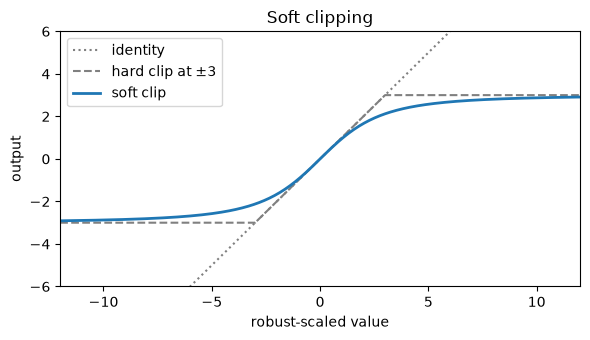

In [5]:
grid = np.linspace(-12, 12, 401)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(grid, grid, color="gray", linestyle=":", label="identity")
ax.plot(
    grid,
    np.clip(grid, -SOFT_CLIP, SOFT_CLIP),
    color="gray",
    linestyle="--",
    label="hard clip at ±3",
)
ax.plot(grid, grid / np.sqrt(1 + (grid / SOFT_CLIP) ** 2), linewidth=2, label="soft clip")
ax.set(
    xlim=(-12, 12),
    ylim=(-6, 6),
    xlabel="robust-scaled value",
    ylabel="output",
    title="Soft clipping",
)
ax.legend()
plt.tight_layout()
plt.show()

hard clip은 3을 넘는 값을 모두 3으로 만들어, 5와 10을 구분하지 못합니다. soft clip은 순서를 유지합니다. 5는 2.57, 10은 2.87이 되어, 큰 값끼리도 여전히 구분됩니다.

### 1.3 power transform과 무엇이 다른가 — 학습 행 범위 밖의 값

v2의 power 멤버(Yeo-Johnson)도 학습 행만 보면 마라톤 날을 잘 눌러 줍니다. 차이는 테스트 행에 학습 행 범위 밖의 값이 올 때 나타납니다. Yeo-Johnson은 열마다 지수 $\lambda$를 학습 행에 맞추는데, $\lambda$가 0에서 멀면 범위 밖의 값을 아주 크게 키울 수 있습니다. 테스트 행 세 개를 넣어 봅니다: 평범한 날(7,000보), 비 온 날(2,000보), 아파서 누워 있던 날(0보).

In [6]:
test_steps = np.array([7000, 2000, 0], dtype=float)

power = PowerTransformer(method="yeo-johnson", standardize=True).fit(steps[:, None])
robust = RobustSoftClip().fit(steps[:, None])

print(f"학습 행에 맞춘 Yeo-Johnson λ = {power.lambdas_[0]:.2f}")
display(
    pd.DataFrame(
        {
            "걸음 수": test_steps,
            "power (v2 멤버)": power.transform(test_steps[:, None]).ravel(),
            "robust + soft clip (2.5 멤버)": robust.transform(test_steps[:, None]).ravel(),
        },
        index=["평범한 날", "비 온 날", "아파서 누운 날"],
    ).map(lambda v: f"{v:,.4g}")
)
print(
    "학습 행 8개의 power 값 범위:",
    power.transform(steps[:, None]).min().round(2),
    "~",
    power.transform(steps[:, None]).max().round(2),
)

학습 행에 맞춘 Yeo-Johnson λ = -2.54


,걸음 수,power (v2 멤버),robust + soft clip (2.5 멤버)
평범한 날,"7,000",-0.1004,0.04347
비 온 날,"2,000",-52.67,-2.461
아파서 누운 날,0,-1.34e+10,-2.687


학습 행 8개의 power 값 범위: -1.34 ~ 2.15


학습 행에서 power 값은 $-1.34$에서 $2.15$ 사이였습니다. 그런데 $\lambda = -2.54$에서는 학습 행 최솟값(5,900)보다 작은 값이 급격히 커져서, 2,000보는 $-52.7$, 0보는 $-1.3 \times 10^{10}$이 됩니다. robust + soft clip은 무슨 값이 와도 $\pm 3$ 안입니다.

실제 추론에서는 power 변환 전에 학습 행 평균에서 표준편차 12배 밖의 값을 자르고(`OUTLIER_SIGMA`), 모델 안에서도 z 값을 $\pm 100$으로 자릅니다. 그래서 무한대가 모델에 들어가지는 않습니다. 하지만 모델이 학습 때 본 값(대부분 몇 이내)보다 훨씬 큰 값이 들어가는 것은 같습니다. 2.5 논문이 적은 "outlier-prone feature distributions"에 대한 robustness는 이런 경우를 말하는 것으로 읽었습니다.

### 1.4 멤버를 어떻게 섞나 (여기서 정한 것)

논문은 robust scaling + soft clipping을 "quantile transformations and standard scaling"과 함께 쓴다고만 적었고, Yeo-Johnson을 계속 쓰는지는 적지 않았습니다. 이 저장소는 다음처럼 정했습니다.

- 2.5 멤버 종류는 `("quantile", "robust")`입니다. v2의 `("quantile", "power")`에서 power 자리를 robust가 대신합니다.
- standard scaling은 모델 안의 z-정규화가 이미 하므로 따로 멤버를 두지 않습니다.
- SVD 성분은 v2처럼 quantile 멤버에만 붙입니다(논문: "in some of the estimators").
- 범주형 열은 v2와 같습니다. 기본값(`one_hot="all"`)에서 범주가 20개 이하인 열은 모든 멤버에서 one-hot으로 펼칩니다. 그보다 많은 열은 robust 멤버에서 power 멤버처럼 번호 그대로 두고, quantile 멤버만 번호를 섞습니다.

어느 묶음을 쓸지는 가중치가 정합니다(`default_inference`). Hub의 `config.json`에 적힌 값이 있으면 그것을 쓰고, 없으면 모델 구조가 2.5이면 v2.5 묶음입니다. 실제 크기 모델로 확인합니다.

In [7]:
for arch in ["v2", "v2.5"]:
    for task in ["classification", "regression"]:
        model = with_architecture(paper(task), arch).build_model()
        print(f"{arch:4} {task:14} → {default_inference(model, task)}")

v2   classification → {'n_estimators': 4, 'member_kinds': ('quantile', 'power')}
v2   regression     → {'n_estimators': 8, 'member_kinds': ('quantile', 'power')}


v2.5 classification → {'n_estimators': 4, 'member_kinds': ('quantile', 'robust')}
v2.5 regression     → {'n_estimators': 8, 'member_kinds': ('quantile', 'robust')}


멤버 수는 v2 논문 기본값(분류 4개, 회귀 8개) 그대로이고, 멤버 종류를 차례로 돌려 씁니다. 회귀는 멤버 절반의 y에도 power transform을 겁니다. 작은 모델로 앙상블을 만들어 멤버마다 무엇을 하는지 꺼내 봅니다. 학습하지 않은 모델이라 예측은 보지 않고 멤버 구성만 봅니다. 입력은 feature 3개, 학습 행 30개짜리 무작위 표입니다.

In [8]:
rng = np.random.default_rng(0)
x_small = rng.normal(size=(30, 3))
y_class = rng.integers(0, 2, size=30)
y_value = x_small @ np.array([1.0, -0.5, 0.2]) + 0.1 * rng.normal(size=30)

tiny = CellTransformer(
    CellTransformerConfig(
        emsize=16, nlayers=1, nhead=2, features_per_group=3, n_thinking_rows=4, n_out=10
    )
)
borders = torch.linspace(-3, 3, 11)  # 구간 10개의 경계 (회귀 앙상블을 만들려면 필요하다)

member_rows = []
for kinds in ["v2", "v2.5"]:
    member_kinds = resolve_member_kinds(
        kinds
    )  # 묶음 이름 → 종류 목록, 예: "v2.5" → ("quantile", "robust")
    clf = EnsembleClassifier(tiny, n_estimators=4, member_kinds=member_kinds).fit(x_small, y_class)
    reg = EnsembleRegressor(tiny, borders, n_estimators=8, member_kinds=member_kinds).fit(
        x_small, y_value
    )
    for task, ens in [("분류", clf), ("회귀", reg)]:
        for i, (prep, x_member) in enumerate(zip(ens.preprocessors_, ens.X_trains_, strict=True)):
            member_rows.append(
                {
                    "묶음": kinds,
                    "task": task,
                    "멤버": i + 1,
                    "전처리": prep.member.kind,
                    "y power (회귀)": prep.member.target_power if task == "회귀" else "—",
                    "모델 입력 열 수": x_member.shape[1],
                }
            )

members = pd.DataFrame(member_rows)
display(
    members[members["task"] == "분류"]
    .set_index(["묶음", "멤버"])
    .drop(columns=["task", "y power (회귀)"])
    .unstack(0)
)
display(
    members[members["task"] == "회귀"].set_index(["묶음", "멤버"]).drop(columns="task").unstack(0)
)

전처리           모델 입력 열 수     
묶음        v2      v2.5        v2 v2.5
멤버                                   
1   quantile  quantile         8    8
2      power    robust         4    4
3   quantile  quantile         8    8
4      power    robust         4    4

전처리           y power (회귀)        모델 입력 열 수     
묶음        v2      v2.5           v2   v2.5        v2 v2.5
멤버                                                       
1   quantile  quantile        False  False         8    8
2      power    robust        False  False         4    4
3   quantile  quantile         True   True         8    8
4      power    robust         True   True         4    4
5   quantile  quantile        False  False         8    8
6      power    robust        False  False         4    4
7   quantile  quantile         True   True         8    8
8      power    robust         True   True         4    4

분류 멤버 4개는 quantile과 robust를 번갈아 씁니다. quantile 멤버는 원래 열 3개, 분위수 열 3개, SVD 성분 1개, 샘플 식별자 열 1개로 모델 입력이 8열이고, robust 멤버는 변환한 열 3개에 샘플 식별자 열 1개를 더한 4열입니다. 회귀 멤버 8개는 2개씩 y power를 껐다 켰다 하므로, 종류마다 정확히 절반이 y power 멤버입니다.

## 2. 논문에 없어서 여기서 정한 것

2.5 논문은 구조 변경 네 가지를 문장 몇 개로 적었고, 학습 데이터와 학습 설정은 거의 공개하지 않았습니다. 이 저장소가 2.5를 재현하며 정한 것을 모두 모읍니다. 목표는 논문을 그대로 옮기는 것이 아니라, 공개된 정보로 학습해서 benchmark 숫자를 다시 내는 것입니다.

| 무엇 | 논문이 적은 것 | 여기서 정한 것 | 코드 |
|---|---|---|---|
| 임베딩 크기, head 수 | 적지 않음 | v2 그대로 192, 6 | `recipes/tabpfn_v2.py` `ARCHITECTURES` |
| thinking 행 | 64개, pretraining 때 학습, attention sink 역할 | 행마다 벡터 하나를 모든 열에 씀, 열 이름표는 더하지 않음, 학습 행 앞에 둬 key·value로 씀, 출력은 버림, 처음 값 0.02 × 표준정규 난수 | `models/cell_transformer.py` |
| 회귀 MLP encoder | 회귀의 linear encoder를 2층 MLP로 | feature 셀 묶음 encoder에 적용, Linear → GELU → Linear(hidden = E), y encoder는 linear 그대로 | `models/cell_transformer.py` |
| prior | "substantially" 개선, 더 많은 행·feature | v2 재현과 같은 TabICL graph SCM prior(`graph_scm`) | `priors/graph_scm.py` |
| 학습 설정 | 공개 안 됨 | v2 설정에서 시작: batch 64, lr 2e-4, warmup 10k. 회귀는 QK-clip 250, 붕괴로 되돌릴 때 lr × 0.5 | `recipes/tabpfn_v2.py` `paper` |
| 긴 표 학습 | 공개 안 됨 (추론 권장 크기만: 행 50,000, feature 2,000) | 2단계 `long_tables`: 학습 행 512~8,192 log 균등, feature 최대 500, 셀 400,000, 가중치만 가져와 lr 5e-5로 20k step, micro batch 1 | `recipes/tabpfn_v2.py` `long_tables` |
| 추론 멤버 | robust scaling + soft clipping(RealMLP)을 quantile·standard와 함께, 일부 멤버에 SVD | `("quantile", "robust")`: power 자리를 robust가 대신, standard는 모델 안 z-정규화, SVD는 quantile 멤버에만, 범주형은 v2처럼(범주 20개 이하는 one-hot, 그보다 많으면 robust 멤버에서 번호 그대로) | `recipes/tabpfn_v2.py` `MEMBER_KINDS_V2_5` |
| robust 세부 | 적지 않음 | 사분위 폭이 0이면 2 / (최대 − 최소), soft clip 폭 3 | `inference/preprocessing.py` `RobustSoftClip` |
| 실데이터 fine-tune (Real-TabPFN-2.5) | 실데이터 43개로 fine-tune | 하지 않음 | — |